In [1]:
# import gevent.monkey #* Handle errors between requests and grequests
# gevent.monkey.patch_all()

import pandas as pd
import numpy as np
from pprint import pprint
import time
import os
import matplotlib.pyplot as plt
from typing import *
import math
import datetime

In [2]:
#* Constants
startingDate = "2013-01-01"
endingDate = "2023-12-31"

#* Format des données horraires
startingDateInt = "2020010100"
endingDateInt = "2023123123"
regions_departements = {
    "Auvergne-Rhône-Alpes": [
        1, 3, 7, 15, 26, 38, 42, 43, 63, 69, 73, 74
    ],
    "Bourgogne-Franche-Comté": [
        21, 25, 39, 58, 70, 71, 89, 90
    ],
    "Bretagne": [
        22, 29, 35, 56
    ],
    "Centre-Val de Loire": [
        18, 28, 36, 37, 41, 45
    ],
    # "Corse": [
    #     20
    # ],
    "Grand Est": [
        8, 10, 51, 52, 54, 55, 57, 67, 68, 88
    ],
    "Hauts-de-France": [
        2, 59, 60, 62, 80
    ],
    "Ile-de-France": [
        75, 77, 78, 91, 92, 93, 94, 95
    ],
    "Nouvelle-Aquitaine": [
        16, 17, 19, 23, 24, 33, 40, 47, 64, 79, 86, 87
    ],
    "Normandie": [
        14, 27, 50, 61, 76
    ],
    "Occitanie": [
        9, 11, 12, 30, 31, 32, 34, 46, 48, 65, 66, 81, 82
    ],
    "Pays de la Loire": [
        44, 49, 53, 72, 85
    ],
    "PACA": [
        4, 5, 6, 13, 83, 84
    ]
}


In [3]:
# Constants


APIurl = "https://tabular-api.data.gouv.fr/api/resources/"


#* Colonnes pour les fichier météo en jour
relevantColsDay = ["NUM_POSTE",#* Numéro de poste,
                    "LAT", #* L'attitude
                    "LON", #* Longitude
                    "DATE", #* Date
                    "RR", #* Quantité de précipipation
                    "TN", #* Température minimal à l'abri
                    "TX", #* Température maximal à l'abri
                    "TM", #* Température moyenne à l'abri
                    "DG", #* Durée du gel
                    "FFM", #* Force moyenne des vents à 10m
                ]

#* Colonnes pour les fichiers météo en heure
relevantColsHOR = [ "NUM_POSTE",#* Numéro de poste,
                    "AAAAMMJJHH", #* Date et heure
                    "LAT", #* L'attitude
                    "LON", #* Longitude
                    "RR1", #* Quantitée des précipitations sur l'heure
                    # "DRR1", #* Durée des précipitations sur une heure
                    "FF", #* Force moyenne du vent à 10m
                    # "FF2", #* Force moyenne du vent à 2m
                    "T", #* Température à l'abri
                    "TD", #* Température au point de rosé
                    "TN", #* Température minimal à l'abri
                    "TX", #* Température maximal à l'abri
                    "DG", #* Durée du gel en mn
                    # "TNSOL", #* Température au sol
                    # "TN50", #* Température à 50 cm du sol
                    "U", #* Humidité (%)
                    "UN",#* Humidité min (%)
                    "UX", #* Humidité max (%)
                    "DHUMI40", #* durée humidité <=40%
                    "DHUMI80", #* durée humidité <=80%
                    ]

# reponse = requests.get(APIurl+dataIds[0])

# data = pd.DataFrame(reponse.json()['data'])
# data


In [ ]:
#* GetIds from files 
def getIds(fileName):
    ids = []
    with  open(fileName) as fileIds:
        for link in fileIds:
            ids.append(link[-37:-1])
    return ids
meteoDayIds =  getIds("ressourcesLink.txt")
meteoHORIds =  getIds("HORLinks.txt")
nbDep = len(meteoDayIds)

In [ ]:
""" SWAGGER AND PROFILE"""
# swagger = requests.get("https://tabular-api.data.gouv.fr/api/resources/c79aaafe-8017-4d2b-8884-57b5391da5bc/swagger/")
# for l in swagger.iter_lines():
#     print(l)
def getProfile():
    import requests
    reponse = requests.get("https://tabular-api.data.gouv.fr/api/resources/9aad7600-6ba8-47c6-b31b-79c8631d7ae9/profile/")
    print(reponse.json()['profile'])
# getProfile()

In [ ]:
#* Test call API
query = (
"page_size=50"
"&columns=NUM_POSTE,AAAAMMJJ,TN,TX,TM,TNSOL,TN50,DG,FF2M,DRR"
"&AAAAMMJJ__greater="+startingDate+""
"&AAAAMMJJ__less="+endingDate+""
)
reponse = requests.get("https://tabular-api.data.gouv.fr/api/resources/c79aaafe-8017-4d2b-8884-57b5391da5bc/data/?"+query)
pprint(reponse.json())
if reponse.status_code==200:
    data = pd.DataFrame(reponse.json()['data'])
else:
    pprint(reponse.json())
    
data.head()

In [4]:
def getFileNameMet(step:Literal["raw","cleaned"],delta:Literal["ByDay","ByHour"]=None,departementNumber:int=None,filled:bool=False):
    metoBase = "meteo_"
    number = str(departementNumber).zfill(2)
    if step=="raw":
        return os.path.join(step+"Data","meteo",delta,metoBase+number+".csv")

    return os.path.join(step+"Data","meteo","fill" if filled else "unfilled",delta,metoBase+number+".csv")

def getFileNameEnr(step:Literal["raw","cleaned"],region:str=None,year:int=None):
    if step=="raw":
        # print(os.path.join(step+"Data",dataSource,f"eCO2mix_RTE_{region}_Annuel-Definitif_{year}.zip"))
        return os.path.join(step+"Data","energy",f"eCO2mix_RTE_{region.replace(" ","-")}_Annuel-Definitif_{year}.xls")
    else:
        return os.path.join(step+"Data","energy",f"Consommation_{region.replace(" ","-")}.csv")

In [ ]:
#* Get all data :
# baseAPI = "https://tabular-api.data.gouv.fr/api/resources/"
# query = (
#         "/data/?"
#         "page_size=200"
#         "&columns="+",".join(relevantColsDay)+""
#         "&AAAAMMJJ__greater="+startingDate+"" 
#         "&AAAAMMJJ__less="+endingDate+""
#     )

# #* ~3min per departement
# def getDepMeteoData(id:str):
#     import requests

#     isNext = True
    
#     data = pd.DataFrame()
#     totalRequest = baseAPI+id+query

#     #* Loop throw all pages
#     while isNext:
#         reponse = requests.get(totalRequest)

#         if reponse.status_code==200:
#             reponse = reponse.json()

#             if data.shape[0]>0:
#                 data = pd.concat([data,pd.DataFrame(reponse['data'])]) #* Concat all data together
#             else:
#                 data = pd.DataFrame(reponse['data'])

#             if reponse["links"]["next"]:
#                 totalRequest = reponse["links"]["next"]
#                 time.sleep(0.01) #* The API limit rate is 100/seconds
#             else: #* End of the data
#                 isNext = False

#             print(f"\rPage : {reponse['meta']['page']} / {reponse['meta']['total']/reponse['meta']['page_size']} ",end='', flush=True)

#         else:
#             print('ERROR DURING REQUEST',reponse.json())
#             break
#     print('')
#     return data


# def getMeteoData():
#     for dep,meteoId in list(enumerate(meteoIds))[0:1]:

#         print(f"Département {dep} / {len(meteoIds)}")
#         meteoData = getDepMeteoData(meteoId)
#         print("data size ",meteoData.shape)
#         # time.sleep(5)
#         # meteoData.to_csv(getFileName("raw","meteo",dep))

# getMeteoData()

In [ ]:
#* -------------- ASYNCRHONOUS BY DAY--------------------
#* Get all data :
apiPageSizeLimit =200
baseAPI = "https://tabular-api.data.gouv.fr/api/resources/"
query = (
        "/data/?"
        "page_size="+str(apiPageSizeLimit)+""
        "&columns="+",".join(relevantColsDay)+""
        "&AAAAMMJJ__greater="+startingDate+"" 
        "&AAAAMMJJ__less="+endingDate+""
    )
data = pd.DataFrame()

def handleApiResult(reponse):
    global data
    # print("API HANDLER")
    if reponse and reponse.status_code==200:
        reponse = reponse.json()
        # print(f"\rPage : {reponse['meta']['page']} / {reponse['meta']['total']/reponse['meta']['page_size']} ",end='', flush=True)
        # print(len(reponse["data"]))
        data = pd.concat([data,pd.DataFrame(reponse['data'])]) #* Concat all data together

    else:
        print('ERROR DURING REQUEST',reponse.json())

#* ~3min per departement
def getDepMeteoDataAsync(dep,id:str):
    global data
    import grequests
    
    totalRequest = baseAPI+id+query
    #* first request : 
    req = grequests.get(totalRequest)
    reponse = grequests.map([req])[0]
    if reponse.status_code==200:
        reponse = reponse.json()

        data = pd.DataFrame(reponse['data'])
        nbPages = math.floor(reponse["meta"]["total"]/reponse["meta"]["page_size"]) #* We already get the first page
        print(f"First call done, Calls to make :{nbPages} ")
        #* Loop throw all pages
        pendingCall = []
        page = 2
        while page < nbPages+1:
            currentRequest = totalRequest + "&page="+str(page)
            pendingCall.append(grequests.get(currentRequest)) 
            if page%100==0: #* We make call by batch of 100
                results = grequests.map(pendingCall)
                print("")
                # print(f"Results call for dep {dep}: {results}")
                for result in results:
                    handleApiResult(result)
                time.sleep(1) #* The API limit rate is 100/seconds
                pendingCall = []
                # break
                # print('call Made ',page," / ",nbPages)
            print('\rcall Made ',page," / ",nbPages,end='',flush=True)

            page +=1

        results = grequests.map(pendingCall)
        for result in results:
            handleApiResult(result)
        # print(f"Results call for dep {dep}: {data}")  

    else:
        print('ERROR DURING REQUEST',reponse)

    print('')
    return data


def getMeteoData():
    # for dep,meteoId in list(enumerate(meteoIds)):
    for dep in regions_departements['Bretagne']:
        meteoId = meteoDayIds[dep]
        print(f"Département {dep} / {len(meteoDayIds)}")
        meteoData = getDepMeteoDataAsync(dep+1,meteoId)
        print(meteoData.head())
        print("data size ",meteoData.shape)
        # time.sleep(5)
        meteoData.to_csv(getFileName("raw","meteo",delta="ByDay",departementNumber=dep))
getMeteoData()

In [ ]:
#* -------------- ASYNCRHONOUS BY HOUR--------------------
#* Get all data :
apiPageSizeLimit =200
baseAPI = "https://tabular-api.data.gouv.fr/api/resources/"
query = (
        "/data/?"
        "page_size="+str(apiPageSizeLimit)+""
        "&columns="+",".join(relevantColsHOR)+""
        "&AAAAMMJJHH__greater="+startingDateInt+"" 
        "&AAAAMMJJHH__less="+endingDateInt+""
    )
data = pd.DataFrame()

def handleApiResult(reponse):
    global data
    # print("API HANDLER")
    if reponse and reponse.status_code==200:
        reponse = reponse.json()
        # print(f"\rPage : {reponse['meta']['page']} / {reponse['meta']['total']/reponse['meta']['page_size']} ",end='', flush=True)
        data = pd.concat([data,pd.DataFrame(reponse['data'])]) #* Concat all data together

    else:
        print('ERROR DURING REQUEST',reponse.json())

#* ~3min per departement
def getDepMeteoDataAsync(dep,id:str):
    global data
    import grequests
    
    totalRequest = baseAPI+id+query
    print(totalRequest)
    #* first request : 
    req = grequests.get(totalRequest)
    reponse = grequests.map([req])[0]
    if reponse.status_code==200:
        reponse = reponse.json()

        data = pd.DataFrame(reponse['data'])
        nbPages = math.floor(reponse["meta"]["total"]/reponse["meta"]["page_size"]) #* We already get the first page
        print(f"First call done, Calls to make :{nbPages} ")
        #* Loop throw all pages
        pendingCall = []
        page = 2
        while page < nbPages+1:
            currentRequest = totalRequest + "&page="+str(page)
            pendingCall.append(grequests.get(currentRequest)) 
            if page%100==0: #* We make call by batch of 100
                results = grequests.map(pendingCall)
                # print("")
                # print(f"Results call for dep {dep}: {results}")
                for result in results:
                    handleApiResult(result)
                time.sleep(1) #* The API limit rate is 100/seconds
                pendingCall = []
                # break
            # print('\rnb url to call ',len(pendingCall),end='',flush=True)
            print('\rcall Made ',page," / ",nbPages,end='',flush=True)

            page +=1

        results = grequests.map(pendingCall)
        for result in results:
            handleApiResult(result)
        # print(f"Results call for dep {dep}: {results}")  

    else:
        print('ERROR DURING REQUEST',reponse)

    print('')
    return data


def getMeteoData():
    # for dep,meteoId in list(enumerate(meteoIds)):
    for dep in regions_departements['Bretagne']:
        meteoId = meteoHORIds[dep]
        print(f"Département {dep} / {len(meteoDayIds)}")
        meteoData = getDepMeteoDataAsync(dep+1,meteoId)
        print(meteoData.head())
        print("data size ",meteoData.shape)
        # time.sleep(5)
        meteoData.to_csv(getFileName("raw","meteo",delta="ByHour",departementNumber=dep))
getMeteoData()

**Transform Data**

In [ ]:
#* METEO DAY | Use to filter the dowload to only keep relevant informations 

minDate = 20130101
stats = []
for dep in range(1,3):
    
# for dep in range(1,96):
    print(dep)
    depStr = str(dep).zfill(2)
    dataMeteoRaw = pd.read_csv(os.path.join("rawData","meteo","ByDay",f"Q_{depStr}_previous-1950-2024_RR-T-Vent.csv"),sep=";")
    # print(dataMeteoRaw)
    dataDay = dataMeteoRaw[dataMeteoRaw["AAAAMMJJ"]>=minDate].copy()
    # dataDay["AAAAMMJJ"] = 
    dataDay["DATE"] = pd.to_datetime(dataDay["AAAAMMJJ"],dayfirst=True,format="%Y%m%d").dt.date
    
    dataDay.drop(["AAAAMMJJ"],axis=1, inplace=True)

    dataDayStats = dataDay.drop(["NUM_POSTE","LAT","LON","DATE","NOM_USUEL","ALTI","STATUS_FXI3S","STATUS_DXI3S"],axis=1)
    stats.append(1-dataDayStats.isna().sum()/dataDayStats.shape[0])

    dataDay.to_csv(getFileNameMet("raw","ByDay",dep),index=False)

In [ ]:
unusedCols = ['CM', 'CH', 'N1', 'C1', 'B1', 'N2', 'C2', 'B2', 'N3', 'C3', 'B3',
       'GEOP', 'CL', 'N4', 'B4', 'C4', 'N', 'NBAS', 'DHUMEC', 'DIR', 'HNEIGEF',
       'HNEIGEFI3', 'TUBENEIGE', 'TSNEIGE', 'DIRHOULE', 'HVAGUE', 'PVAGUE',
       'ETATMER', 'TMER', 'VVMER', 'W2', 'W1', 'HNEIGEFI1', 'ESNEIGE',
       'CHARGENEIGE', 'DIF', 'UV_INDICE', 'TLAGON', 'ECOULEMENT', 'TVEGETAUX',
       'DIF2', 'UV', 'DIR2', 'INFRAR', 'INFRAR2', 'UV2', 'SOLNG']
def basicFilterWeatherHOR(dep):
    print(dep,datetime.datetime.now())
    minDate = 2013010100
    depStr = str(dep).zfill(2)
    dataMeteoRaw = pd.read_csv(os.path.join("rawData","meteo","ByHour",f"H_{depStr}_previous-2020-2024.csv"),sep=";",
                               usecols=lambda c: not c.startswith("STATUS_") and not c.startswith("Q") and not c=="NOM_USUEL" and not c=="ALTI" and not c in unusedCols
                               )


    # dataDay = dataMeteoRaw[dataMeteoRaw["AAAAMMJJHH"] >= minDate].copy()
    dataMeteoRaw.insert(0, "dateTime", pd.to_datetime(dataMeteoRaw["AAAAMMJJHH"], format="%Y%m%d%H"))
    # dataDay["DATE"] = 
    dataMeteoRaw.drop(columns=["AAAAMMJJHH"], inplace=True)

    dataDayStats = dataMeteoRaw.drop(["NUM_POSTE","LAT","LON","dateTime"], axis=1)
    fillRate = 1 - dataDayStats.isna().sum() / dataDayStats.shape[0]

    dataMeteoRaw.to_csv(getFileNameMet("raw","ByHour",dep), index=False)
    return fillRate

In [21]:
stats = []
for dep in range(1,3):
    stats.append(basicFilterWeatherHOR(dep))

1 2026-03-28 18:16:49.992241
2 2026-03-28 18:17:35.542398


In [ ]:
from concurrent.futures import ProcessPoolExecutor

def processDep(dep):
    print(dep,datetime.datetime.now())
    minDate = 20130101
    depStr = str(dep).zfill(2)
    dataMeteoRaw = pd.read_csv(
        os.path.join("rawData","meteo","ByDay",f"Q_{depStr}_previous-1950-2024_RR-T-Vent.csv"),
        sep=";",
        usecols=lambda c: not c.startswith("STATUS_") and not c.startswith("Q") and not c=="NOM_USUEL" and not c=="ALTI"
    )

    dataDay = dataMeteoRaw[dataMeteoRaw["AAAAMMJJ"] >= minDate].copy()
    dataDay.insert(0, "DATE", pd.to_datetime(dataDay["AAAAMMJJ"], format="%Y%m%d").dt.date)
    # dataDay["DATE"] = 
    dataDay.drop(columns=["AAAAMMJJ"], inplace=True)

    dataDayStats = dataDay.drop(["NUM_POSTE","LAT","LON","DATE"], axis=1)
    fillRate = 1 - dataDayStats.isna().sum() / dataDayStats.shape[0]

    dataDay.to_csv(getFileNameMet("raw","ByDay",dep), index=False)
    return fillRate

if __name__ =="__main__":
    
    with ProcessPoolExecutor() as executor:
        stats = list(executor.map(processDep, range(1, 96)))

In [5]:
def plotFillRate(stats: list, savePath: str = "fill_rate.pdf") -> pd.DataFrame:
    """
    Rassemble les taux de remplissage de tous les départements
    et affiche un graphique en barres verticales, téléchargeable.
    """
    fillRates = pd.DataFrame(stats).mean(axis=0).sort_values(ascending=True)

    colors = ["#c6efce" if v >= 0.8 else "#ffeb9c" if v >= 0.5 else "#ffc7ce" for v in fillRates.values]

    fig, ax = plt.subplots(figsize=(14, 7))

    bars = ax.bar(fillRates.index, fillRates.values * 100, color=colors, edgecolor="white", width=0.6)

    for bar, val in zip(bars, fillRates.values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            val * 100 + 1,
            f"{val*100:.1f}%",
            va="bottom", ha="center", fontsize=9, rotation=45
        )

    ax.set_ylim(0, 115)
    ax.set_ylabel("Taux de remplissage (%)", fontsize=11)
    ax.set_title("Taux de remplissage moyen par colonne (tous départements)", fontsize=13)
    ax.axhline(y=80, color="orange", linestyle="--", linewidth=1, alpha=0.7, label="Seuil 80%")
    ax.axhline(y=50, color="red",    linestyle="--", linewidth=1, alpha=0.7, label="Seuil 50%")
    ax.legend(fontsize=10)
    ax.tick_params(axis="x", rotation=45)
    ax.set_facecolor("#f9f9f9")

    plt.tight_layout()
    plt.savefig(savePath, dpi=150, bbox_inches="tight")  # ← sauvegarde
    print(f"Graphique sauvegardé dans : {savePath}")
    plt.show()

    return fillRates.to_frame(name="fillRate").rename_axis("colonne")

Graphique sauvegardé dans : fill_rate.pdf


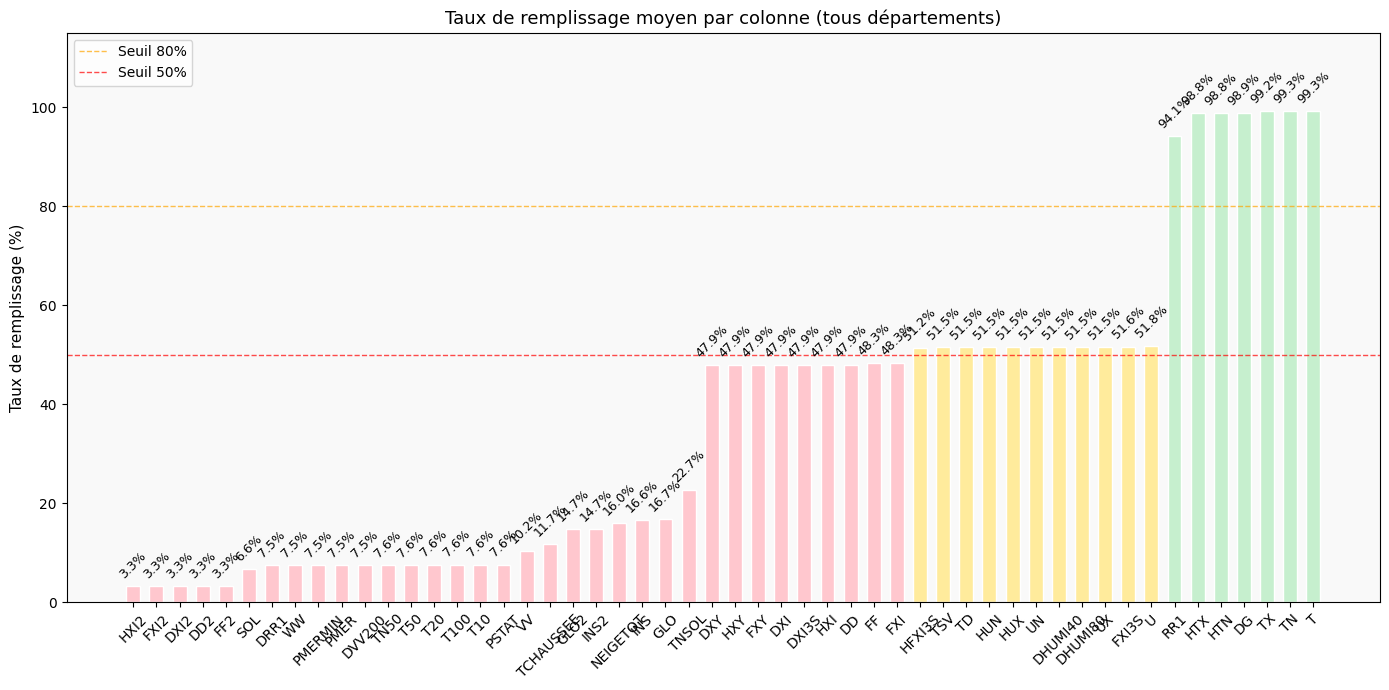

,fillRate
colonne,
HXI2,0.033116
FXI2,0.033116
DXI2,0.033116
DD2,0.033141
FF2,0.033141
SOL,0.065960
DRR1,0.074871
WW,0.075049
PMERMIN,0.075255


In [22]:
plotFillRate(stats)

In [19]:
fillRates = pd.DataFrame(stats).mean(axis=0).sort_values(ascending=True)

fillRates[fillRates < 0.01].index

Index(['CM', 'CH', 'N1', 'C1', 'B1', 'N2', 'C2', 'B2', 'N3', 'C3', 'B3',
       'GEOP', 'CL', 'N4', 'B4', 'C4', 'N', 'NBAS', 'DHUMEC', 'DIR', 'HNEIGEF',
       'HNEIGEFI3', 'TUBENEIGE', 'TSNEIGE', 'DIRHOULE', 'HVAGUE', 'PVAGUE',
       'ETATMER', 'TMER', 'VVMER', 'W2', 'W1', 'HNEIGEFI1', 'ESNEIGE',
       'CHARGENEIGE', 'DIF', 'UV_INDICE', 'TLAGON', 'ECOULEMENT', 'TVEGETAUX',
       'DIF2', 'UV', 'DIR2', 'INFRAR', 'INFRAR2', 'UV2', 'SOLNG'],
      dtype='object')

In [5]:
def getCombinedDatas(delta:Literal["ByHour","ByDay"],scale:Literal["Region","Dep"]) -> List[pd.DataFrame]:
    combinedDatas = []
    for region in regions_departements.keys():

        df = pd.read_csv(os.path.join("datasets",f"{scale}_{delta}",f"{region}-data.csv"),parse_dates=["Date"] if delta=="ByDay" else ["dateTime"],index_col=0)
        combinedDatas.append(df)
    return combinedDatas

In [31]:
for region,df in zip(regions_departements.keys(),getCombinedDatas("ByHour","Region")):
    df.drop(['DRR1',"TN50","TNSOL"],axis=1,inplace=True)
    df.to_csv(os.path.join("datasets",f"Region_ByDay",f"{region}-data.csv"),index=False)

In [ ]:
#* METEO HOR | Use to filter the dowload to only keep relevant informations 

minDate = 2013010100

for dep in range(1,5):
    depStr = str(dep).zfill(2)
    dataMeteoRaw = pd.read_csv(os.path.join("rawData","meteo","ByHour",f"H_{depStr}_previous-2020-2024.csv"),sep=";")
    # print(dataMeteoRaw)
    dataHOR = dataMeteoRaw[dataMeteoRaw["AAAAMMJJHH"]>=minDate][relevantColsHOR]
    print("\r"+depStr,end='')
    dataHOR.to_csv(getFileNameMet("raw","ByHour",dep))

04

In [ ]:
#* Correct the datetime

# from concurrent.futures import ThreadPoolExecutor

# def process_dep(dep):

#     depStr = str(dep).zfill(2)
#     # dataHOR = pd.read_csv(getFileNameMet("raw","ByHour",dep), index_col=0)
    
#     # dataHOR["AAAAMMJJHH"] = pd.to_datetime(dataHOR["AAAAMMJJHH"],dayfirst=True,format="%Y%m%d%H")
#     # dataHOR["DATE"] = dataHOR["AAAAMMJJHH"].dt.date
#     # dataHOR["HOUR"] = dataHOR["AAAAMMJJHH"].dt.hour
    
#     # dataHOR.drop(columns = ["AAAAMMJJHH"], inplace=True)

#     # dataHOR.to_csv(getFileNameMet("cleaned","ByHour",departementNumber=dep),index=False)

#     dataDay = pd.read_csv(getFileNameMet("raw","ByDay",dep))

#     dataDay["AAAAMMJJ"] = pd.to_datetime(dataDay["AAAAMMJJ"],dayfirst=True,format="%Y%m%d")
#     dataDay["DATE"] = dataDay["AAAAMMJJ"].dt.date
    
#     dataDay.drop(columns=["AAAAMMJJ"], inplace=True)
   

#     dataDay.to_csv(getFileNameMet("cleaned","ByDay",departementNumber=dep),index=False)

#     print("\r"+depStr,end='')

# # with ThreadPoolExecutor(max_workers=5) as executor:
# #     executor.map(process_dep, range(3, 5))
#     # executor.map(process_dep, range(1, 96))

In [6]:
#! ============== TO SUPPP
def plotFillRate(stats: list ,delta:str, savePath: str=None) -> pd.DataFrame:
    """
    Rassemble les taux de remplissage de tous les départements
    et affiche un graphique en barres verticales, téléchargeable.
    """
    fillRates = pd.DataFrame(stats).mean(axis=0).sort_values(ascending=True)

    colors = ["#c6efce" if v >= 0.8 else "#ffeb9c" if v >= 0.5 else "#ffc7ce" for v in fillRates.values]

    fig, ax = plt.subplots(figsize=(14, 7))

    bars = ax.bar(fillRates.index, fillRates.values * 100, color=colors, edgecolor="white", width=0.6)

    for bar, val in zip(bars, fillRates.values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            val * 100 + 1,
            f"{val*100:.1f}%",
            va="bottom", ha="center", fontsize=9, rotation=45
        )

    ax.set_ylim(0, 115)
    ax.set_ylabel("Filling rate (%)", fontsize=11)
    ax.set_title(f"Mean filling rate by {delta} features", fontsize=13)
    ax.axhline(y=80, color="orange", linestyle="--", linewidth=1, alpha=0.7, label="Seuil 80%")
    ax.axhline(y=50, color="red",    linestyle="--", linewidth=1, alpha=0.7, label="Seuil 50%")
    ax.legend(fontsize=10)
    ax.tick_params(axis="x", rotation=45)
    ax.set_facecolor("#f9f9f9")

    plt.tight_layout()
    if savePath:
        plt.savefig(savePath, dpi=150, bbox_inches="tight")  # ← sauvegarde
        print(f"Graphique sauvegardé dans : {savePath}")
    plt.show()

    return fillRates.to_frame(name="fillRate").rename_axis("colonne")

In [8]:
def computeFillRateDay(dep):

    dataWeather = pd.read_csv(
        getFileNameMet("cleaned","ByDay",dep,filled=True),
        usecols=lambda c: not c.startswith("STATUS_") and not c.startswith("Q") and c not in ["NUM_POSTE","LAT","LON","DATE","NOM_USUEL","ALTI"]
    )

    fillRate = 1 - dataWeather.isna().sum() / dataWeather.shape[0]

    return fillRate

def computeFillRateHOR(dep):
    print(dep,datetime.datetime.now())
    unusedCols = ['CM', 'CH', 'N1', 'C1', 'B1', 'N2', 'C2', 'B2', 'N3', 'C3', 'B3',
       'GEOP', 'CL', 'N4', 'B4', 'C4', 'N', 'NBAS', 'DHUMEC', 'DIR', 'HNEIGEF',
       'HNEIGEFI3', 'TUBENEIGE', 'TSNEIGE', 'DIRHOULE', 'HVAGUE', 'PVAGUE',
       'ETATMER', 'TMER', 'VVMER', 'W2', 'W1', 'HNEIGEFI1', 'ESNEIGE',
       'CHARGENEIGE', 'DIF', 'UV_INDICE', 'TLAGON', 'ECOULEMENT', 'TVEGETAUX',
       'DIF2', 'UV', 'DIR2', 'INFRAR', 'INFRAR2', 'UV2', 'SOLNG']

    dataWeather = pd.read_csv(
        getFileNameMet("raw","ByHour",dep),
        usecols=lambda c: not c.startswith("STATUS_") and not c.startswith("Q") and c not in ["NUM_POSTE","LAT","LON","dateTime","NOM_USUEL","ALTI"] and not c in unusedCols
    )

    fillRate = 1 - dataWeather.isna().sum() / dataWeather.shape[0]

    return fillRate


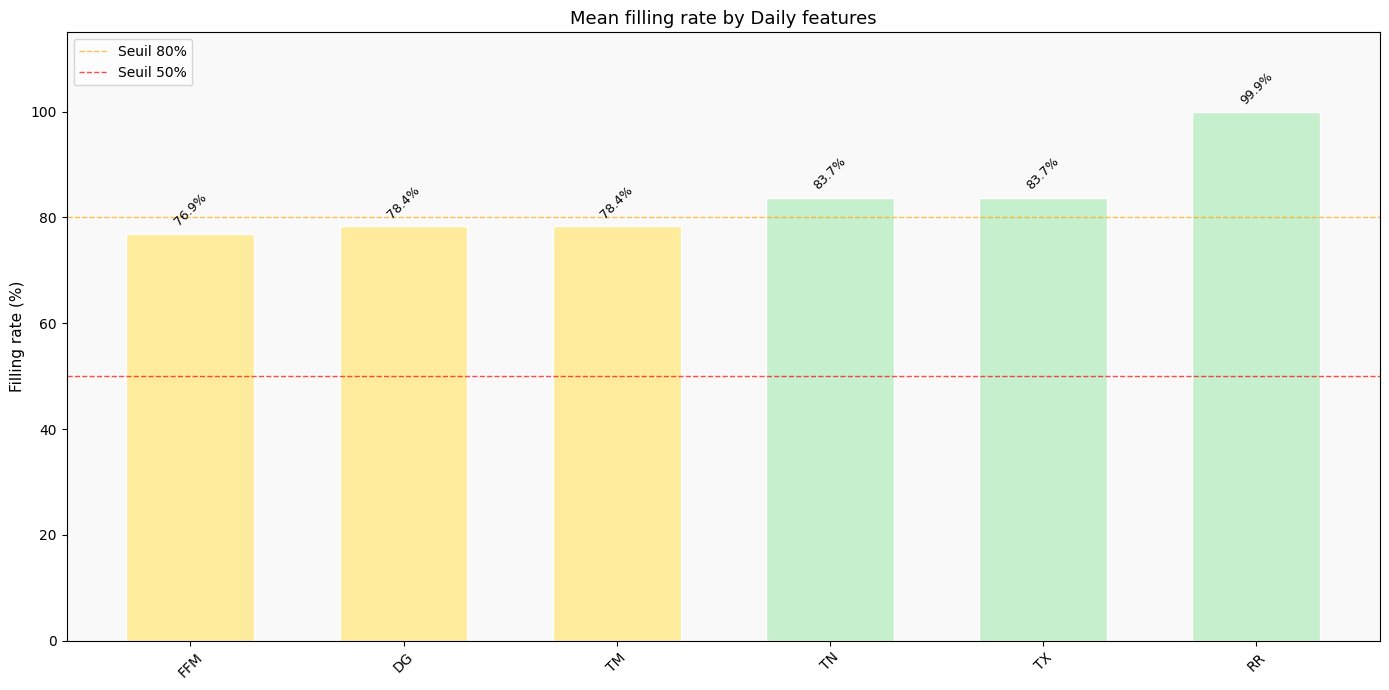

,fillRate
colonne,
FFM,0.769116
DG,0.783637
TM,0.784005
TN,0.837326
TX,0.837330
RR,0.998712


In [9]:
stats= map(computeFillRateDay,range(1,96))
# for dep in range(1,96):
#     stats += computeFillRateDay(dep)
plotFillRate(stats,"Daily") 

1 2026-03-31 00:21:40.820077
2 2026-03-31 00:21:41.076414
3 2026-03-31 00:21:41.189096
4 2026-03-31 00:21:41.439499
5 2026-03-31 00:21:41.658245
6 2026-03-31 00:21:41.962098
7 2026-03-31 00:21:42.182552
8 2026-03-31 00:21:42.527056
9 2026-03-31 00:21:42.686639
10 2026-03-31 00:21:42.919440
11 2026-03-31 00:21:43.116177
12 2026-03-31 00:21:43.381565
13 2026-03-31 00:21:43.703241
14 2026-03-31 00:21:43.890503
15 2026-03-31 00:21:44.151280
16 2026-03-31 00:21:44.397860
17 2026-03-31 00:21:44.506180
18 2026-03-31 00:21:44.668377
19 2026-03-31 00:21:44.990905
20 2026-03-31 00:21:45.255260
21 2026-03-31 00:21:45.843485
22 2026-03-31 00:21:46.087197
23 2026-03-31 00:21:46.293710
24 2026-03-31 00:21:46.498501
25 2026-03-31 00:21:46.673880
26 2026-03-31 00:21:46.872986
27 2026-03-31 00:21:47.178682
28 2026-03-31 00:21:47.329046
29 2026-03-31 00:21:47.546931
30 2026-03-31 00:21:47.756311
31 2026-03-31 00:21:48.042251
32 2026-03-31 00:21:48.246714
33 2026-03-31 00:21:48.454179
34 2026-03-31 00:21

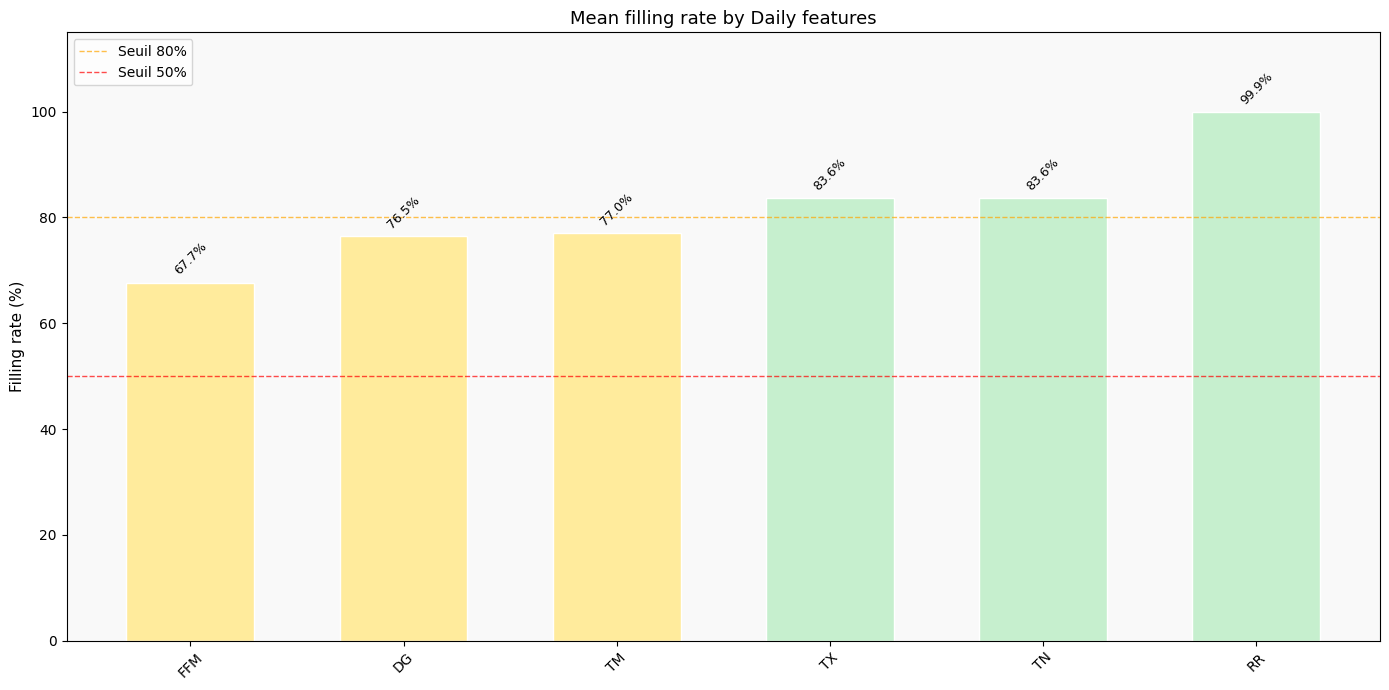

,fillRate
colonne,
FFM,0.676710
DG,0.764847
TM,0.770250
TX,0.835989
TN,0.835990
RR,0.998548


In [12]:

stats= map(computeFillRateDay,range(1,96))
# for dep in range(1,96):
#     stats += computeFillRateDay(dep)
plotFillRate(stats,"Daily") 

In [ ]:
#* Energy excel to csv and filter


    
    


Auvergne-Rhône-Alpes
Bourgogne-Franche-Comté
Bretagne
Centre-Val de Loire
Grand Est
Hauts-de-France
Ile-de-France
Nouvelle-Aquitaine
Normandie
Occitanie
Pays de la Loire
PACA


In [ ]:
#* Divide consommation by 1000 and sort by dateTime
for region in regions_departements.keys():
    consommationDf = pd.read_csv(getFileNameEnr("cleaned",region=region))
    
    
    # consommationDf = consommationDf[["Date","Heures","Consommation"]]
    # print(consommationDf)
    consommationDf.to_csv(getFileNameEnr("cleaned",region=region),index=False)

In [13]:
#* Meteo by Day 

# for dep in range(1,nbDep+1):
for dep in [2]:
    rawData = pd.read_csv(getFileName("raw","meteo",delta="ByDay",departementNumber=dep-1),index_col=0)

    cleanData = rawData.drop(['NUM_POSTE'],axis=1)
    cleanData.groupby(['AAAAMMJJ']).mean() #* Compute the mean by day on differents stations

    cleanData.to_csv(getFileName("cleaned","meteo",delta="ByDay",departementNumber=dep))

# plt.plot(cleanData["AAAAMMJJ"],cleanData["TN"])


In [13]:
#* Correction des import sur les Météo horraires 

# from concurrent.futures import ThreadPoolExecutor

def process_dep(dep):

    depStr = str(dep).zfill(2)
    # dataHOR = pd.read_csv(getFileNameMet("raw","ByHour",dep), index_col=0)
    
    # dataHOR["AAAAMMJJHH"] = pd.to_datetime(dataHOR["AAAAMMJJHH"],dayfirst=True,format="%Y%m%d%H")
    # dataHOR["DATE"] = dataHOR["AAAAMMJJHH"].dt.date
    # dataHOR["HOUR"] = dataHOR["AAAAMMJJHH"].dt.hour
    
    # dataHOR.drop(columns = ["AAAAMMJJHH"], inplace=True)

    # dataHOR.to_csv(getFileNameMet("cleaned","ByHour",departementNumber=dep),index=False)

    dataHor = pd.read_csv(getFileNameMet("cleaned","ByHour",dep))

    dataHor["dateTime"] = pd.to_datetime(dataHor["DATE"].astype(str) + dataHor["HOUR"].astype(str).str.zfill(2), format="%Y-%m-%d%H")

    dataHor.drop(["FF2","DATE","HOUR"],axis=1,inplace=True)
    
    # print(dataHor)

    dataHor.to_csv(getFileNameMet("cleaned","ByHour",departementNumber=dep),index=False)

    print("\r"+depStr,dataHor.shape,end='')

# with ThreadPoolExecutor(max_workers=5) as executor:
#     executor.map(process_dep, range(1,96))
for dep in range(1,96):
    process_dep(dep)


95 (263089, 19))

**RECUPERATION DES ESTIMATIONS RTE**

In [ ]:
rteFileName = "eCO2mix_RTE_Annuel-Definitif_"
yearsDf = []
#* Convert Excel to csv
for year in range(2013,2025):
    rteData = pd.read_csv(os.path.join("rawData","rte",f"{rteFileName}{year}.xls"),sep="\t",encoding="latin-1",usecols=["Date","Heures","Consommation","Prévision J-1","Prévision J"])
    rteData.dropna(inplace=True)
    yearsDf.append(rteData)
    print(f"year : {year}, len : {rteData.shape}")
rteData = pd.concat(yearsDf)
rteData.to_csv(os.path.join("cleanedData","rte",f"rteEstimation.csv"),index=False)

year : 2020, len : (17568, 5)
year : 2021, len : (17520, 5)
year : 2022, len : (17520, 5)
year : 2023, len : (17520, 5)


In [1]:
yearsDf =[]
for year in range(2020, 2024):
    rteData = pd.read_csv(
        os.path.join("rawData", "rte", f"{rteFileName}{year}.xls"),
        sep="\t",
        encoding="latin-1",
    )

    rteData.columns = rteData.columns.str.strip()

    # Sélectionner les colonnes par position car les colonnes sont mal nommée/corrompu
    rteData = rteData.iloc[:, [1,2, 3, 4, 5]]  # Date, Heures, Conso, Prev J-1, Prev J
    rteData.columns = ["Date", "Heures", "Consommation", "Prévision J-1", "Prévision J"]
    # print(rteData.head(2))

    # Supprimer uniquement les lignes sans Consommation
    rteData.dropna(subset=["Consommation"], inplace=True)
    yearsDf.append(rteData)
    # print(f"year : {year}, len : {rteData.shape}")
rteData = pd.concat(yearsDf)
rteData.to_csv(os.path.join("cleanedData","complement",f"rteEstimation.csv"),index=False)


NameError: name 'pd' is not defined

In [66]:
# deps = [str(i).zfill(2) for i in range(1, 96)]  # 01 à 95

fill_rates = []

for dep in range(1, 96):

    path = getFileNameMet("cleaned", "ByDay", dep)
    df = pd.read_csv(path)
    fill_rate = df.notna().mean() * 100  
    fill_rates.append(fill_rate)


# Moyenne sur tous les départements
summary = pd.DataFrame(fill_rates).mean().round(2).sort_values()
summary.name = "Remplissage moyen (%)"

summary

FF2M           1.19
DRR            5.10
TN50           5.87
TNSOL         12.62
FFM           24.49
DG            46.26
TM            48.69
TX            65.34
TN            65.35
RR            98.52
NUM_POSTE    100.00
DATE         100.00
AAAAMMJJ     100.00
Name: Remplissage moyen (%), dtype: float64

In [17]:
set(pd.date_range("2013-01-01","2024-12-31",freq="D"))


{Timestamp('2019-01-23 00:00:00'),
 Timestamp('2024-03-03 00:00:00'),
 Timestamp('2014-03-11 00:00:00'),
 Timestamp('2021-08-17 00:00:00'),
 Timestamp('2013-06-19 00:00:00'),
 Timestamp('2015-10-29 00:00:00'),
 Timestamp('2019-05-05 00:00:00'),
 Timestamp('2022-08-28 00:00:00'),
 Timestamp('2022-09-27 00:00:00'),
 Timestamp('2018-03-02 00:00:00'),
 Timestamp('2017-05-05 00:00:00'),
 Timestamp('2014-10-12 00:00:00'),
 Timestamp('2022-07-16 00:00:00'),
 Timestamp('2024-07-19 00:00:00'),
 Timestamp('2014-07-28 00:00:00'),
 Timestamp('2024-08-30 00:00:00'),
 Timestamp('2013-04-10 00:00:00'),
 Timestamp('2017-09-18 00:00:00'),
 Timestamp('2024-07-29 00:00:00'),
 Timestamp('2020-08-01 00:00:00'),
 Timestamp('2015-06-27 00:00:00'),
 Timestamp('2022-10-10 00:00:00'),
 Timestamp('2021-08-10 00:00:00'),
 Timestamp('2015-02-18 00:00:00'),
 Timestamp('2024-02-24 00:00:00'),
 Timestamp('2015-12-10 00:00:00'),
 Timestamp('2016-02-10 00:00:00'),
 Timestamp('2017-10-04 00:00:00'),
 Timestamp('2017-11-